# REGULARIZED REGRESSION

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## **1. Load the dataset**

In [2]:
# Load data
housing = pd.read_csv('https://raw.githubusercontent.com/alwanmr/Portfolio/refs/heads/main/01-housing-value-regression/boston.csv')
print(np.shape(housing))
housing.head()

(506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [3]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  black    506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [4]:
housing.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


### Dataset Explanation


1. crim = per capita crime rate by town
2. zn = proportion of residential land zoned for lots over 25,000 sq.ft.
3. indus = proportion of non-retail business acres per town.
4. chas = Charles River dummy variable (1 if tract bounds river; 0 otherwise)
5. nox = nitric oxides concentration (parts per 10 million)
6. rm = average number of rooms per dwelling
7. age = proportion of owner-occupied units built prior to 1940
8. dis = weighted distances to five Boston employment centres
9. rad = index of accessibility to radial highways
10. tax = full-value property-tax rate per $10,000

11. ptratio = pupil-teacher ratio by town
12. black = 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town
13. lstat = % lower status of the population
14. medv = Median value of owner-occupied homes in $1000's

### **Variables in the dataset that can be used to predict house prices.**
Variables in the "boston housing" dataset in the context of supervised learning can be divided into two: features (predictors) and target.

- Features are variables evaluated as having a potential role in predicting the target. All variables currently not included as the target can be assumed as variables that can be used to predict house prices. Later, features can be filtered further (if necessary) through the EDA (Exploratory Data Analysis) process and multicollinearity checks.
> Feature = `crim`, `zn`, `indus`, `chas`, `nox`, `rm`, `age`, `dis`, `rad`, `tax`, `ptratio`, `black`, and `lstat`.

- Target is the numerical variable that you want to predict. In this case, the **`medv`** variable is designated as the target (the median value of owner-occupied homes).
> Target = `medv`.

### **Reasons why this data is relevant to the house price prediction case study.**

All features have characteristics that can be considered relevant to house prices (at least conceptually), either directly or indirectly. For example:
- **Property characteristics**: `rm` can represent the size or capacity of a house through the number of rooms, and `age`  can represent the property's age.
- **Accessibility**: `rad` and `tax` can provide information regarding highway accessibility, location characteristics, and regional tax burdens.
- **Neighborhood / socioeconomic**: `crim`, `zn`, `indus`, `chas`, `dis`, `ptratio`, `black`, and `lstat` can represent community features, land-use zoning, regional facility ratios, demographic attributes, and local socioeconomic conditions that influence property values.
- **Environmental**: `nox` can represent the environmental and air quality conditions of an area, potentially influencing its appeal and property value.

### **Most relevant variables to use when the analytical goal is to understand the determinants of house prices.**

Features such as `rm`, `lstat`, `crim`, `nox`, `dis`, `rad`, and `chas` have a fairly strong relevance to house prices (at least conceptually) because these features represent property characteristics, environmental conditions, and location that can directly or indirectly influence property values. However, this conceptual relevance cannot yet be used as a basis for determining feature selection.

Correlation analysis against `medv` an be used as an initial step to compare the strength of each feature's relationship with the target.

In [5]:
# Variable comparison and its relevance to house price can be answered using correlation analysis
housing.corr(numeric_only=True)["medv"].sort_values(ascending=False)

,medv
medv,1.000000
rm,0.695360
zn,0.360445
black,0.333461
dis,0.249929
chas,0.175260
age,-0.376955
rad,-0.381626
crim,-0.388305
nox,-0.427321


> Based on correlation with `medv`, `rm` and `lstat` mshow the strongest linear relationship, with values of 0.695 and -0.738. Features such as `ptratio`, `indus`, `tax`, `nox`, and `crim` also show a relatively stronger linear relationship compared to other features. These correlation results can be used as an initial overview of the relationship between features and the target, but they are not yet sufficient to determine feature selection because they do not account for relationships between features and multicollinearity.

## **2. Data Preprocessing**

### **Splitting Data**
Data is split into: train, validation, and test sets.

In [6]:
# Split train test
from sklearn.model_selection import train_test_split

feature = housing.drop(columns='medv')
target = housing[['medv']]

# First splitting: pretrain and test
feature_housing_pretrain, feature_housing_test, target_housing_pretrain, target_housing_test = train_test_split(feature, target, test_size=0.20, random_state=77)

# Second splitting: train and validation
feature_housing_train, feature_housing_validation, target_housing_train, target_housing_validation = train_test_split(feature_housing_pretrain, target_housing_pretrain, test_size=0.20, random_state=77)

> Training data is the splitting result used to build the model.

> Validation data is used during the model development process to select the best hyperparameters.

> Test data is kept until the end while maintaining raw data, functioning to measure model performance against data never used during the development process.

This division helps ensure that model-based decisions are not merely relevant to historical data because the model and hyperparameter selection process is performed using data different from the training data (validation data). Meanwhile, evaluation on the test data—which remains untouched during the development process—provides an overview of model performance on new data. Thus, the selected model is evaluated not only based on its performance in learning available data, but also on its ability to generate predictions on new data.

### Data Cleaning

In [7]:
# Missing value check
missing_count = feature_housing_train.isnull().sum()
missing_percent = (feature_housing_train.isnull().sum() / len(feature_housing_train)) * 100
print(f"Missing Value Count:\n{missing_count}")
print(f"\nMissing Value Percentage:\n{missing_percent}")

# Duplicated data check
duplicate_count = feature_housing_train.duplicated().sum()
print(f"\nDuplicate Row Count: {duplicate_count}")

Missing Value Count:
crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
black      0
lstat      0
dtype: int64

Missing Value Percentage:
crim       0.0
zn         0.0
indus      0.0
chas       0.0
nox        0.0
rm         0.0
age        0.0
dis        0.0
rad        0.0
tax        0.0
ptratio    0.0
black      0.0
lstat      0.0
dtype: float64

Duplicate Row Count: 0


### Exploratory Data Analysis
 Analisis eksplorasi awal untuk memahami distribusi data.

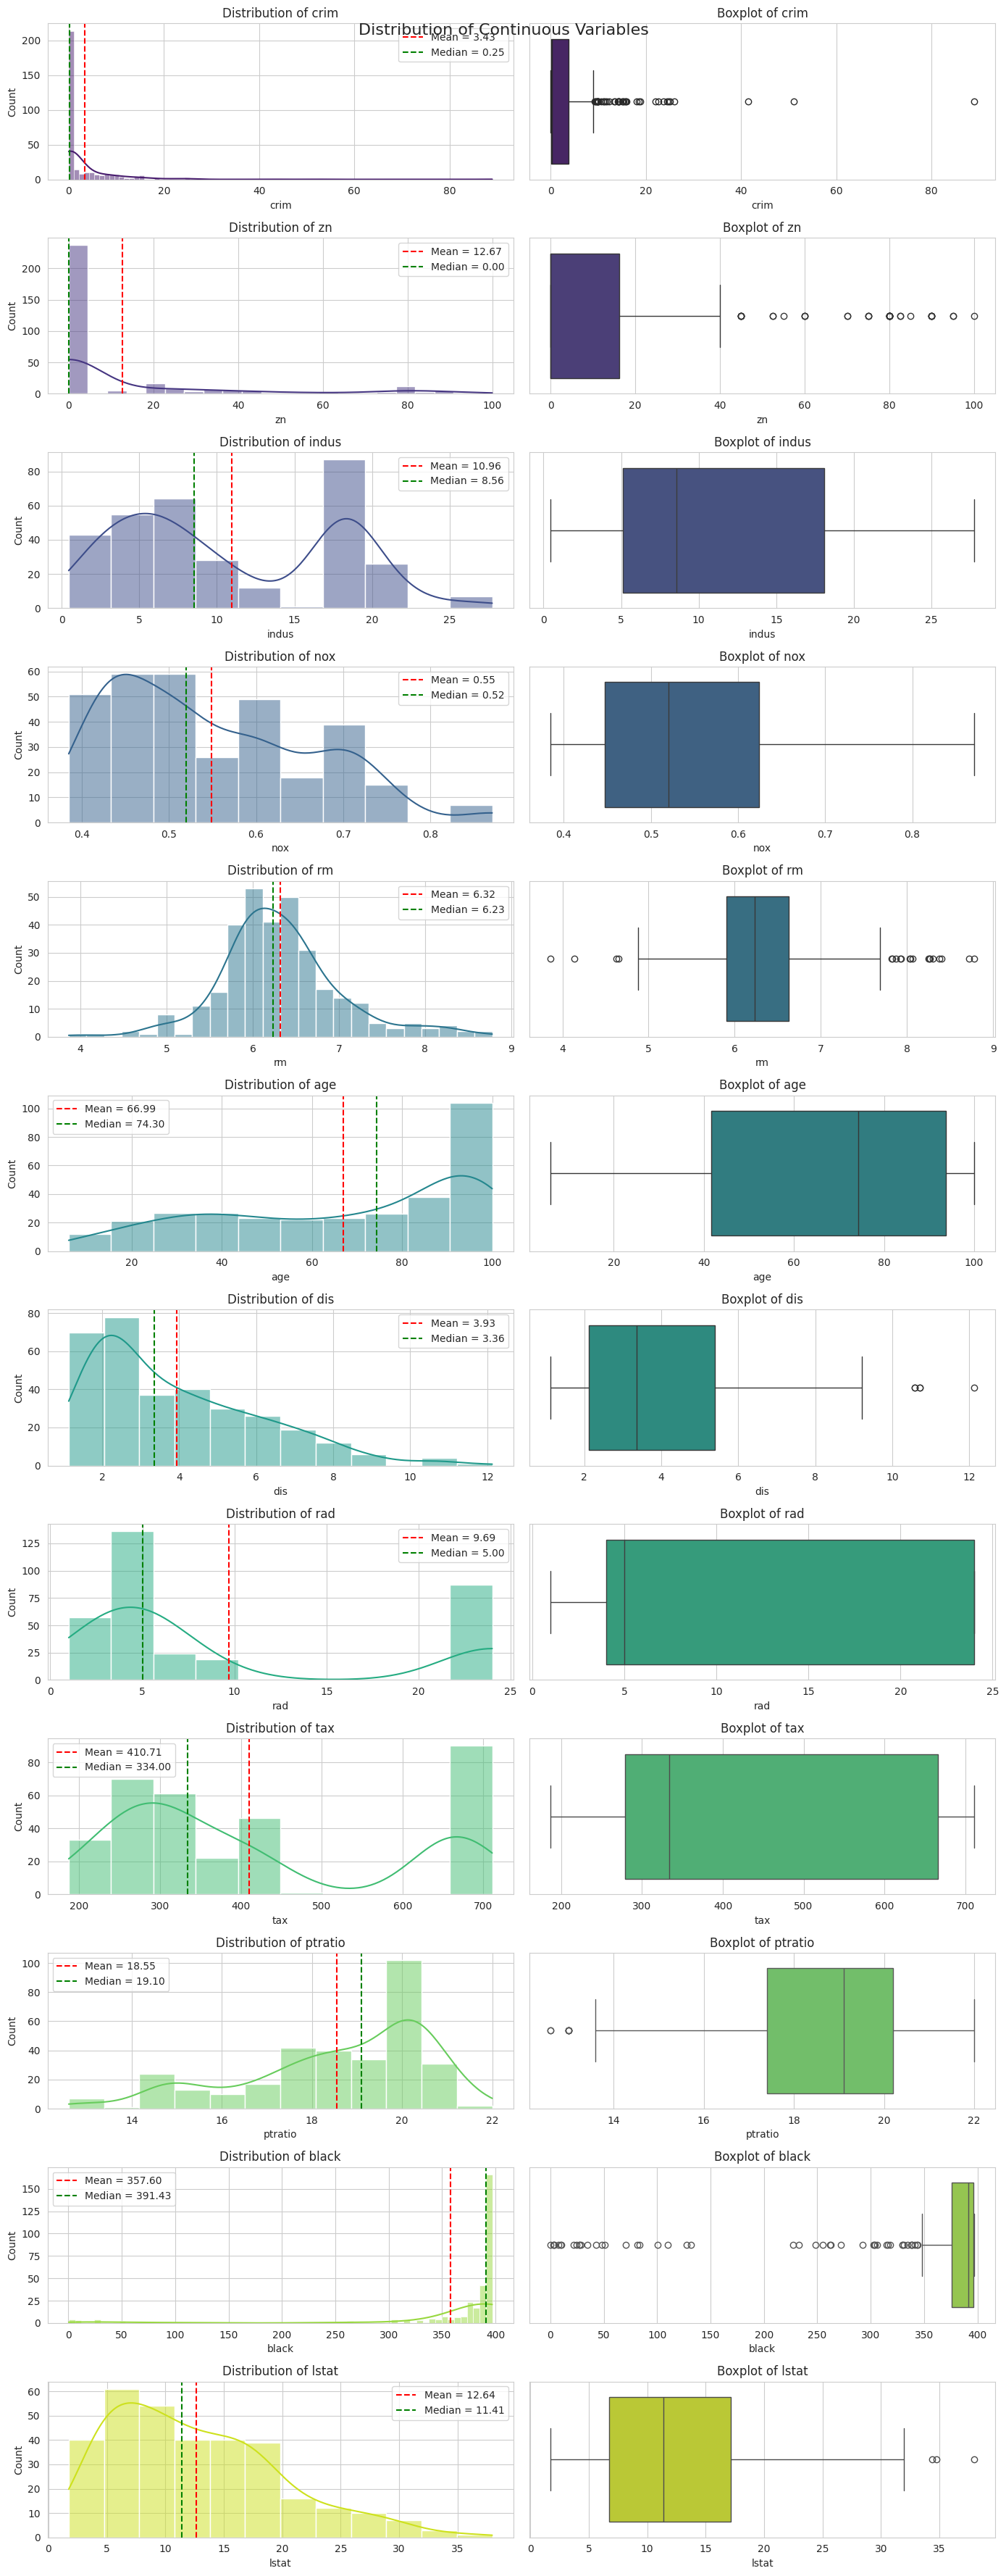

In [8]:
continuous_vars = {'crim': '',
                   'zn': '',
                   'indus': '',
                   'nox': '',
                   'rm': '',
                   'age': '',
                   'dis': '',
                   'rad': '',
                   'tax': '',
                   'ptratio': '',
                   'black': '',
                   'lstat': ''}

# Assign color to each variable based on viridis palette
colors = sns.color_palette('viridis', n_colors=len(continuous_vars))
continuous_vars = dict(zip(continuous_vars.keys(), colors))

sns.set_style('whitegrid')

fig, axes = plt.subplots(len(continuous_vars), 2, figsize=(14, 36))

for ax, (var, color) in enumerate(continuous_vars.items()):

    # Histogram + KDE
    sns.histplot(data=feature_housing_train, x=var, kde=True, color=color, ax=axes[ax, 0])

    mean = feature_housing_train[var].mean()
    median = feature_housing_train[var].median()

    axes[ax, 0].axvline(mean, color='red', linestyle='--', label=f'Mean = {mean:.2f}')
    axes[ax, 0].axvline(median, color='green', linestyle='--', label=f'Median = {median:.2f}')
    axes[ax, 0].set_title(f'Distribution of {var}')
    axes[ax, 0].legend()

    # Boxplot
    sns.boxplot(data=feature_housing_train, x=var, color=color, ax=axes[ax, 1])

    axes[ax, 1].set_title(f'Boxplot of {var}')

plt.suptitle('Distribution of Continuous Variables', fontsize=16)
plt.tight_layout()
plt.show()

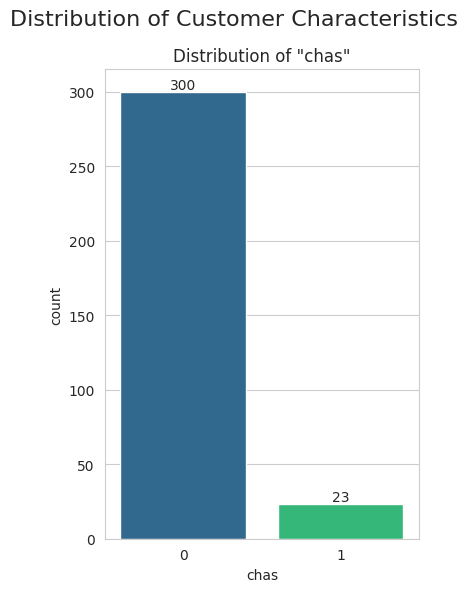

In [9]:
# Categorical Variable Distribution
sns.set_style('whitegrid')

fig, ax = plt.subplots(figsize=(4, 6))

# Countplot
sns.countplot(data=feature_housing_train, x='chas', color='black', ax=ax)

# Palette
colors = sns.color_palette('viridis', n_colors=feature_housing_train['chas'].nunique())

for patch, color in zip(ax.patches, colors):
  patch.set_facecolor(color)

ax.set_title('Distribution of "chas"')

# Menambahkan jumlah di atas bar
for container in ax.containers:
  ax.bar_label(container)

plt.suptitle('Distribution of Customer Characteristics', fontsize=16)
plt.tight_layout()
plt.show()

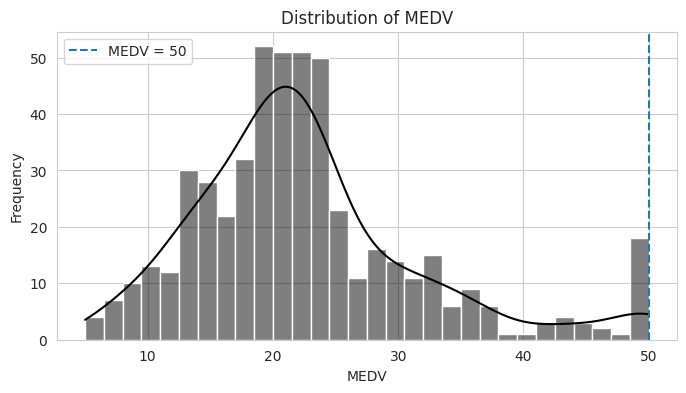

In [10]:
# Target (`medv`) distribution
plt.figure(figsize=(8, 4))

sns.histplot(data=housing,
             x='medv',
             kde=True,
             bins=30,
             color='black')

plt.axvline(x=50,
            linestyle='--',
            label='MEDV = 50')

plt.title('Distribution of MEDV')
plt.xlabel('MEDV')
plt.ylabel('Frequency')
plt.legend()
plt.show()

#### EDA Analysis
Several variables show observations located outside the boxplot whiskers, identifying them as potential outliers. However, the presence of these observations is not yet sufficient grounds for data removal, as extreme observations may represent actual conditions in the dataset.

Additionally, the documentation for the Boston Housing dataset contains the statement: "Variable #14 seems to be censored at 50.00 (corresponding to a median price of $50,000).". This means the `medv` variable exhibits an indication of censoring at the value of 50.00. Consequently, observations with MEDV = 50 potentially do not represent the true price value if the actual value lies above that threshold. Therefore, these values cannot be directly considered outliers or invalid data and should ideally be retained in the dataset.

## **3. Correlation Analysis and Feature Selection**

### Correlation Plot

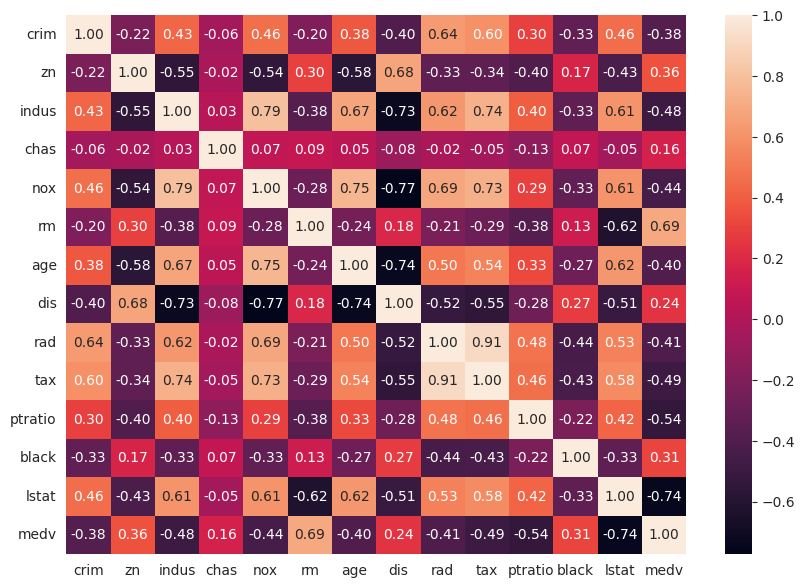

In [11]:
# heatmap correlation
housing_train = pd.concat([feature_housing_train, target_housing_train], axis=1)
corr = housing_train.corr()

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.show()

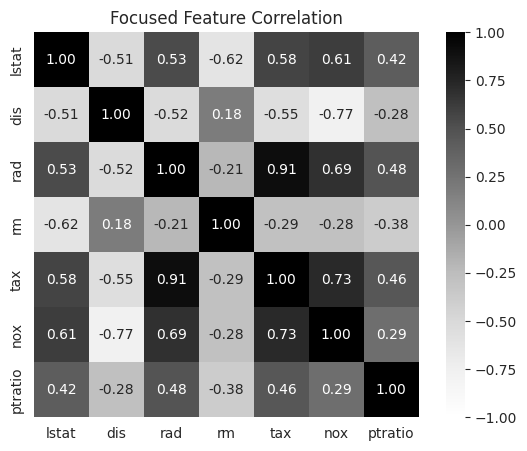

In [12]:
selected_corr = housing_train[
    ['lstat', 'dis', 'rad', 'rm', 'tax', 'nox', 'ptratio']
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    selected_corr,
    annot=True,
    fmt='.2f',
    cmap='Greys',
    vmin=-1,
    vmax=1,
    square=True
)

plt.title('Focused Feature Correlation')
plt.show()

### Multicollinearity

In [13]:
# Calculate VIF scores
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant

# Add intercept column, VIF requires a constant (intercept) term to calculate correctly
X = add_constant(feature_housing_train)

# Change DataFrame to array format, then wrap it as DataFrame (vif_df)
vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']
vif_df

,feature,vif_score
1,crim,1.800701
2,zn,2.295048
3,indus,4.223429
4,chas,1.067905
5,nox,4.996314
6,rm,2.015910
7,age,3.183120
8,dis,3.962085
9,rad,7.808406
10,tax,8.842757


Features with high VIF score: **`rad`**, **`tax`**. Considering the correlation between the features and the target, the results obtained are:
> **`rad`** and **`tax`** mare candidates for dropping due to high multicollinearity. **`tax`** was chosen to be retained because it has a relatively stronger relationship with the target (**`medv`**).

In [14]:
# drop redundant features (`rad`)
selectedfeature_housing_train = feature_housing_train.drop(columns=['rad'])
selectedfeature_housing_validation = feature_housing_validation.drop(columns=['rad'])
selectedfeature_housing_test = feature_housing_test.drop(columns=['rad'])

#### Recheck VIF

In [15]:
# calculate VIF scores
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant

# Add intercept column, VIF requires a constant (intercept) term to calculate correctly
X = add_constant(selectedfeature_housing_train)

# Change DataFrame to array format, then wrap it as DataFrame (vif_df)
vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']
vif_df

,feature,vif_score
1,crim,1.663123
2,zn,2.285018
3,indus,3.941660
4,chas,1.054903
5,nox,4.766807
6,rm,1.966571
7,age,3.155059
8,dis,3.962006
9,tax,3.753593
10,ptratio,1.632869


### Feature Selection

Feature selection is carried out by considering the relationship between variables and the degree of multicollinearity, particularly based on VIF values. Features with high multicollinearity can be considered for reduction so that the model has a simpler structure, as well as more stable and easily interpretable coefficients. However, feature selection should not be based solely on correlation with the target, because a high correlation with the target may actually indicate important predictive information.

> Based on correlation and VIF analysis, the variables `rad` and `tax` exhibit high multicollinearity with a correlation of 0,91. One of the variables can be removed to reduce redundancy. `rad` was chosen to be dropped because `tax` has a stronger correlation with `medv`, and the VIF of `tax` dropped from 8.84 to 3.75 after `rad` was removed.

Consequently, there are two feature sets that can be compared: the use of all features and the use of the selected features by removing `rad`. The selected feature set has lower multicollinearity, but it cannot yet be concluded to have superior performance. Performance comparison needs to be conducted during the modeling and validation stages to determine the approach that better supports clear and consistent decision-making.


## **4. Model Training**

In [16]:
# Data Preparation

# Full feature set
X_housing_train = feature_housing_train
X_housing_validation = feature_housing_validation

# Selected feature set (drop redundant feature: RAD)
X_housing_train_selected = selectedfeature_housing_train
X_housing_validation_selected = selectedfeature_housing_validation

# Target
y_housing_train = target_housing_train.to_numpy().ravel()
y_housing_validation = target_housing_validation.to_numpy().ravel()

### A. Full Features

#### Ridge

In [17]:
# RIDGE - FULL FEATURES

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Create Ridge model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
ridge_reg_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.001))])
ridge_reg_pointzeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.01))])
ridge_reg_pointone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.1))])
ridge_reg_one = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=1))])
ridge_reg_ten = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=10))])
ridge_reg_hundred = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

# Train models with different alpha values using training set
ridge_reg_pointzerozeroone.fit(X_housing_train, y_housing_train)
ridge_reg_pointzeroone.fit(X_housing_train, y_housing_train)
ridge_reg_pointone.fit(X_housing_train, y_housing_train)
ridge_reg_one.fit(X_housing_train, y_housing_train)
ridge_reg_ten.fit(X_housing_train, y_housing_train)
ridge_reg_hundred.fit(X_housing_train, y_housing_train)

Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

In [18]:
# RIDGE VALIDATION - FULL FEATURES

from sklearn.metrics import mean_squared_error

# List of alpha values used for Ridge
ridge_alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Storing the entire Ridge models with various alpha values
ridge_models = [ridge_reg_pointzerozeroone,
                ridge_reg_pointzeroone,
                ridge_reg_pointone,
                ridge_reg_one,
                ridge_reg_ten,
                ridge_reg_hundred]

# Calculating RMSE on the validation set
for model, alpha in zip(ridge_models, ridge_alphas):

  # Predicting target on the validation set
  y_predict_validation = model.predict(X_housing_validation)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housing_validation, y_predict_validation))
  print(f'RMSE of Ridge regression model with alpha = {alpha}: {rmse}')

RMSE of Ridge regression model with alpha = 0.001: 4.6299811101820625
RMSE of Ridge regression model with alpha = 0.01: 4.629946606299117
RMSE of Ridge regression model with alpha = 0.1: 4.629606751712764
RMSE of Ridge regression model with alpha = 1: 4.626695689039754
RMSE of Ridge regression model with alpha = 10: 4.627111421048979
RMSE of Ridge regression model with alpha = 100: 4.968064937995205


In [19]:
# Coefficients

ridge_best = ridge_reg_one
ridge_model = ridge_best.named_steps['ridge']

coef_df = pd.DataFrame({
    'feature':['intercept'] + feature_housing_train.columns.tolist(),
    'coefficient':[ridge_model.intercept_] + list(ridge_model.coef_)
})

coef_df

,feature,coefficient
0,intercept,22.745201
1,crim,-1.012589
2,zn,1.143534
3,indus,-0.030858
4,chas,0.460950
5,nox,-2.244181
6,rm,2.586733
7,age,-0.010549
8,dis,-3.615268
9,rad,2.956592


#### LASSO

In [20]:
# LASSO - FULL FEATURES
from sklearn.linear_model import Lasso

# Create LASSO model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
Lasso_reg_pointzerozerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.0001))])
Lasso_reg_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.001))])
Lasso_reg_pointzeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.01))])
Lasso_reg_pointone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.1))])
Lasso_reg_one = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=1))])
Lasso_reg_ten = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

# Train models with different alpha values using training set
Lasso_reg_pointzerozerozeroone.fit(X_housing_train, y_housing_train)
Lasso_reg_pointzerozeroone.fit(X_housing_train, y_housing_train)
Lasso_reg_pointzeroone.fit(X_housing_train, y_housing_train)
Lasso_reg_pointone.fit(X_housing_train, y_housing_train)
Lasso_reg_one.fit(X_housing_train, y_housing_train)
Lasso_reg_ten.fit(X_housing_train, y_housing_train)

Pipeline(steps=[('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

In [21]:
# LASSO VALIDATION - FULL FEATURES

# List of alpha values used for LASSO
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10]

# Storing the entire LASSO models with various alpha values
lasso_models = [Lasso_reg_pointzerozerozeroone,
                Lasso_reg_pointzerozeroone,
                Lasso_reg_pointzeroone,
                Lasso_reg_pointone,
                Lasso_reg_one,
                Lasso_reg_ten]

# Calculating RMSE on the validation set
for model, alpha in zip(lasso_models, lasso_alphas):

  # Predicting target on the validation set
  y_predict_validation = model.predict(X_housing_validation)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housing_validation, y_predict_validation))

  print(f'RMSE of Lasso regression model with alpha = {alpha}: {rmse}')

RMSE of Lasso regression model with alpha = 0.0001: 4.629972723680264
RMSE of Lasso regression model with alpha = 0.001: 4.629877086293422
RMSE of Lasso regression model with alpha = 0.01: 4.627870454164843
RMSE of Lasso regression model with alpha = 0.1: 4.648614521123664
RMSE of Lasso regression model with alpha = 1: 5.289871032689882
RMSE of Lasso regression model with alpha = 10: 8.911259614138766


In [22]:
# Coefficients
lasso_best = Lasso_reg_pointzeroone
lasso_model = lasso_best.named_steps['lasso']

coef_df = pd.DataFrame({
    'feature':['intercept'] + feature_housing_train.columns.tolist(),
    'coefficient':[lasso_model.intercept_] + list(lasso_model.coef_)
})

coef_df

,feature,coefficient
0,intercept,22.745201
1,crim,-0.997456
2,zn,1.134521
3,indus,-0.006077
4,chas,0.453083
5,nox,-2.242702
6,rm,2.584856
7,age,-0.000000
8,dis,-3.594716
9,rad,2.934890


### B. Selected Features

#### Ridge

In [23]:
# RIDGE - SELECTED FEATURES

# Create Ridge model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
ridge_selected_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.001))])
ridge_selected_pointzeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.01))])
ridge_selected_pointone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.1))])
ridge_selected_one = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=1))])
ridge_selected_ten = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=10))])
ridge_selected_hundred = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

# Train models with different alpha values using training set
ridge_selected_pointzerozeroone.fit(X_housing_train_selected, y_housing_train)
ridge_selected_pointzeroone.fit(X_housing_train_selected, y_housing_train)
ridge_selected_pointone.fit(X_housing_train_selected, y_housing_train)
ridge_selected_one.fit(X_housing_train_selected, y_housing_train)
ridge_selected_ten.fit(X_housing_train_selected, y_housing_train)
ridge_selected_hundred.fit(X_housing_train_selected, y_housing_train)

Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

In [24]:
# RIDGE VALIDATION - SELECTED FEATURES

# List of alpha values used for Ridge
ridge_alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Storing the entire Ridge models with various alpha values
ridge_selected_models = [ridge_selected_pointzerozeroone,
                         ridge_selected_pointzeroone,
                         ridge_selected_pointone,
                         ridge_selected_one,
                         ridge_selected_ten,
                         ridge_selected_hundred]

# Calculating RMSE on the validation set
for model, alpha in zip(ridge_selected_models, ridge_alphas):

  # Predicting target on the validation set
  y_predict_validation = model.predict(X_housing_validation_selected)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housing_validation, y_predict_validation))
  print(f'RMSE of Selected Ridge model with alpha = {alpha}: {rmse}')

RMSE of Selected Ridge model with alpha = 0.001: 4.701159042484891
RMSE of Selected Ridge model with alpha = 0.01: 4.701169418494112
RMSE of Selected Ridge model with alpha = 0.1: 4.701274028300969
RMSE of Selected Ridge model with alpha = 1: 4.702402441787622
RMSE of Selected Ridge model with alpha = 10: 4.719861245914778
RMSE of Selected Ridge model with alpha = 100: 5.013805068643941


In [25]:
# Coefficients
ridge_selected_best = ridge_selected_pointzeroone
ridge_selected_model = ridge_selected_best.named_steps['ridge']

coef_df = pd.DataFrame({
    'feature':['intercept'] + selectedfeature_housing_train.columns.tolist(),
    'coefficient':[ridge_selected_model.intercept_] + list(ridge_selected_model.coef_)
})

coef_df

,feature,coefficient
0,intercept,22.745201
1,crim,-0.619492
2,zn,1.058252
3,indus,-0.581993
4,chas,0.580218
5,nox,-1.771301
6,rm,2.814858
7,age,-0.181251
8,dis,-3.675456
9,tax,-0.001097


#### LASSO

In [26]:
# LASSO - SELECTED FEATURES

# Create LASSO model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
Lasso_selected_pointzerozerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.0001))])
Lasso_selected_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.001))])
Lasso_selected_pointzeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.01))])
Lasso_selected_pointone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.1))])
Lasso_selected_one = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=1))])
Lasso_selected_ten = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

# Train models with different alpha values using training set
Lasso_selected_pointzerozerozeroone.fit(X_housing_train_selected, y_housing_train)
Lasso_selected_pointzerozeroone.fit(X_housing_train_selected, y_housing_train)
Lasso_selected_pointzeroone.fit(X_housing_train_selected, y_housing_train)
Lasso_selected_pointone.fit(X_housing_train_selected, y_housing_train)
Lasso_selected_one.fit(X_housing_train_selected, y_housing_train)
Lasso_selected_ten.fit(X_housing_train_selected, y_housing_train)

Pipeline(steps=[('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

In [27]:
# LASSO VALIDATION - SELECTED FEATURES

# List of alpha values used for LASSO
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10]

# Storing the entire LASSO models with various alpha values
lasso_selected_models = [Lasso_selected_pointzerozerozeroone,
                         Lasso_selected_pointzerozeroone,
                         Lasso_selected_pointzeroone,
                         Lasso_selected_pointone,
                         Lasso_selected_one,
                         Lasso_selected_ten]

# Calculating RMSE on the validation set
for model, alpha in zip(lasso_selected_models, lasso_alphas):

  # Predicting target on the validation set
  y_predict_validation = model.predict(X_housing_validation_selected)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housing_validation, y_predict_validation))
  print(f'RMSE of Selected Lasso model with alpha = {alpha}: {rmse}')

RMSE of Selected Lasso model with alpha = 0.0001: 4.701150409993579
RMSE of Selected Lasso model with alpha = 0.001: 4.701077677051354
RMSE of Selected Lasso model with alpha = 0.01: 4.700551752952901
RMSE of Selected Lasso model with alpha = 0.1: 4.709821099554665
RMSE of Selected Lasso model with alpha = 1: 5.289871027365182
RMSE of Selected Lasso model with alpha = 10: 8.911259614138766


In [28]:
# Coefficients
lasso_selected_best = Lasso_selected_pointzeroone
lasso_selected_model = lasso_selected_best.named_steps['lasso']

coef_df = pd.DataFrame({
    'feature':['intercept'] + selectedfeature_housing_train.columns.tolist(),
    'coefficient':[lasso_selected_model.intercept_] + list(lasso_selected_model.coef_)
})

coef_df

,feature,coefficient
0,intercept,22.745201
1,crim,-0.607768
2,zn,1.030836
3,indus,-0.564703
4,chas,0.572662
5,nox,-1.744824
6,rm,2.815648
7,age,-0.160606
8,dis,-3.600097
9,tax,-0.007542


### Validation Set Performance Comparison

In [29]:
ridge_alphas = [0.001, 0.01, 0.1, 1, 10, 100]
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10]
results = []

# List of all model (with all alpha used) with feature set
model_groups = [('Full', 'Ridge', ridge_models, ridge_alphas, X_housing_validation),
                ('Selected', 'Ridge', ridge_selected_models, ridge_alphas, X_housing_validation_selected),
                ('Full', 'Lasso', lasso_models, lasso_alphas, X_housing_validation),
                ('Selected', 'Lasso', lasso_selected_models, lasso_alphas, X_housing_validation_selected)]

# Calculating RMSE for each set model
for feature_set, model_name, models, alphas, X_val in model_groups:

  for model, alpha in zip(models, alphas):

    y_pred = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_housing_validation, y_pred))

    results.append({'Feature Set': feature_set,
                    'Model': model_name,
                    'Alpha': alpha,
                    'RMSE': rmse})

results_df = pd.DataFrame(results)

# Sort descending based on lowest RMSE value
results_df.sort_values('RMSE')

,Feature Set,Model,Alpha,RMSE
3,Full,Ridge,1.0000,4.626696
4,Full,Ridge,10.0000,4.627111
14,Full,Lasso,0.0100,4.627870
2,Full,Ridge,0.1000,4.629607
13,Full,Lasso,0.0010,4.629877
1,Full,Ridge,0.0100,4.629947
12,Full,Lasso,0.0001,4.629973
0,Full,Ridge,0.0010,4.629981
15,Full,Lasso,0.1000,4.648615
20,Selected,Lasso,0.0100,4.700552


Based on the validation RMSE, model alpha combination, and feature set with the best performance was selected as the final model candidate.

- The Ridge model demonstrated relatively stable performance across various alpha values, particularly in the small-to-medium alpha range. Using the Full Feature set, Ridge achieved its best RMSE of 4.6267 at an alpha of `1`, and its performance remained relatively similar from alpha `0.001` to `10`. However, when alpha increased to `100`, the RMSE went up, indicating that excessively strong regularization can degrade model performance.

- Meanwhile, Lasso showed a higher sensitivity to changes in alpha. Lasso yielded its best performance at an alpha of `0.01` with an RMSE of 4.6278, but its performance dropped when alpha was increased, especially at alpha `1` and `10`. This indicates that an excessively large increase in regularization can cause the model to lose information necessary to produce good predictions.

- When compared by feature set, the model with the Full Feature set provided a lower validation RMSE than the model with the Selected Feature set. This indicates that removing `rad` successfully reduced multicollinearity, but did not automatically improve prediction performance.

> Given these characteristics, Ridge is more appropriately used when information from many features needs to be retained-especially when multicollinearity exists among features and a relatively stable model is required to predict house prices. On the other hand, Lasso is more suitable when model simplification and feature selection are important considerations, because the Lasso penalty can shrink certain coefficients down to zero. In the context of house pricing decision-making, Ridge may be more appropriate when the primary focus is obtaining stable predictions while preserving information from various factors, whereas Lasso can be chosen when a simpler model is needed that is easy to interpret based on the most relevant features.


## **5. Model Interpretation**

In [30]:
# Best Ridge model
ridge_best = ridge_reg_one
ridge_model = ridge_best.named_steps['ridge']

ridge_coef_df = pd.DataFrame({
    'feature': ['intercept'] + feature_housing_train.columns.tolist(),
    'coefficient': [ridge_model.intercept_] + list(ridge_model.coef_)
})

# Best LASSO model
lasso_best = Lasso_reg_pointzeroone
lasso_model = lasso_best.named_steps['lasso']

lasso_coef_df = pd.DataFrame({
    'feature': ['intercept'] + feature_housing_train.columns.tolist(),
    'coefficient': [lasso_model.intercept_] + list(lasso_model.coef_)
})

# Comparison Ridge vs LASSO
coef_df = pd.merge(ridge_coef_df, lasso_coef_df, on='feature', suffixes=('_ridge', '_lasso'))

coef_df['abs_ridge'] = coef_df['coefficient_ridge'].abs()
coef_df['abs_lasso'] = coef_df['coefficient_lasso'].abs()

coef_df['lasso_selected'] = coef_df['coefficient_lasso'] != 0

coef_df_sorted = (coef_df.sort_values(by='abs_ridge', ascending=False)
                  .drop(columns=['abs_ridge', 'abs_lasso'])
                  .reset_index(drop=True))

coef_df_sorted

,feature,coefficient_ridge,coefficient_lasso,lasso_selected
0,intercept,22.745201,22.745201,True
1,lstat,-3.903481,-3.923614,True
2,dis,-3.615268,-3.594716,True
3,rad,2.956592,2.934890,True
4,rm,2.586733,2.584856,True
5,tax,-2.381574,-2.378587,True
6,nox,-2.244181,-2.242702,True
7,ptratio,-2.109654,-2.108648,True
8,zn,1.143534,1.134521,True
9,crim,-1.012589,-0.997456,True


### Analysis of Ridge and LASSO Model Coefficients

- Based on the best-performing model results, Ridge uses all features with an `alpha of 1`, whereas LASSO uses all features with an `alpha of 0.01`. Both models utilize standardization so that the coefficient values can be compared based on their absolute magnitudes.

- In the Ridge model, the features with the largest absolute coefficients are `lstat` (-3.9035), `dis` (-3.6153), `rad` (2.9566), and `rm` (2.5867). Negative coefficients indicate an inverse relationship with the predicted `medv`, while positive coefficients indicate a direct relationship. For example, an lstat coefficient of -3.9035 indicates that a one-standard-deviation increase in `lstat` is associated with a decrease in predicted `medv` of approximately 3.90 units. Conversely, a one-standard-deviation increase in `rm` is associated with an increase in predicted `medv` of approximately 2.59 units.

### Ridge and LASSO Comparison

- Most features share a similar direction of relationship and coefficient magnitude. The main difference is observed in `age`, which has a very small coefficient in Ridge (-0.0105) and becomes 0 in LASSO. This demonstrates LASSO's characteristic of performing feature selection by eliminating features whose contributions are deemed less important by the model.

- Meanwhile, Ridge retains all features by shrinking their coefficient values. For features that exhibit multicollinearity, this approach helps maintain coefficient stability without directly removing the features.

### Relevant Features for Pricing

> Based on absolute coefficient magnitudes, `lstat`, `dis`, `rad`, `rm`, `tax`, `nox`, and `ptratio` have the largest relative contributions to predicting house prices in the model. These features warrant attention when understanding house price patterns because changes in their values have a greater relationship with the predicted `medv` compared to features with smaller coefficients.

For example:
- `lstat` and `nox` provide information regarding socio-economic characteristics and environmental conditions associated with house prices in the model.
- `dis` describes the relative distance to employment centers.
- `rm` provides information on the size or capacity characteristics of the dwelling.
- `tax` represents the property tax rate.
- `ptratio` represents the pupil-teacher ratio as a characteristic of educational facilities/neighborhoods.

> These results indicate that model coefficients can be used to understand the direction and magnitude of each feature's relative contribution to price predictions. However, these relationships are strictly within the context of the model and cannot be directly interpreted as causal relationships.

## **6. Model Evaluation**

### Evaluation Metrics

In [31]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

- Ridge Evaluation Metrics

In [32]:
# Training Error

# Prepare prediction result on train data
y_predict_train = ridge_best.predict(X_housing_train)

print('Training Error:')
print('RMSE for training data is {}'.format(np.sqrt(mean_squared_error(y_housing_train, y_predict_train))))
print('MAE for training data is {}'.format(mean_absolute_error(y_housing_train, y_predict_train)))
print('MAPE for training data is {}'.format(mean_absolute_percentage_error(y_housing_train, y_predict_train)))


# Testing Error

# Prepare prediction result on test data
y_predict_test = ridge_best.predict(feature_housing_test)

# Ground truth target
y_housing_test = target_housing_test.to_numpy()
y_housing_test = y_housing_test.reshape(len(y_housing_test),)

print('\nTesting Error:')
print('RMSE for testing data is {}'.format(np.sqrt(mean_squared_error(y_housing_test, y_predict_test))))
print('MAE for testing data is {}'.format(mean_absolute_error(y_housing_test, y_predict_test)))
print('MAPE for testing data is {}'.format(mean_absolute_percentage_error(y_housing_test, y_predict_test)))

Training Error:
RMSE for training data is 4.842410248181918
MAE for training data is 3.344311559808808
MAPE for training data is 0.16261107908135508

Testing Error:
RMSE for testing data is 4.305813428178082
MAE for testing data is 3.324772805053005
MAPE for testing data is 0.17962849749290577


- LASSO Evaluation Metrics

In [33]:
# Training Error

# Prepare prediction result on train data
y_predict_train = lasso_best.predict(X_housing_train)

print('Training Error:')
print('RMSE for training data is {}'.format(np.sqrt(mean_squared_error(y_housing_train, y_predict_train))))
print('MAE for training data is {}'.format(mean_absolute_error(y_housing_train, y_predict_train)))
print('MAPE for training data is {}'.format(mean_absolute_percentage_error(y_housing_train, y_predict_train)))


# Testing Error

# Prepare prediction result on test data
y_predict_test = lasso_best.predict(feature_housing_test)

# Ground truth target
y_housing_test = target_housing_test.to_numpy()
y_housing_test = y_housing_test.reshape(len(y_housing_test),)

print('\nTesting Error:')
print('RMSE for testing data is {}'.format(np.sqrt(mean_squared_error(y_housing_test, y_predict_test))))
print('MAE for testing data is {}'.format(mean_absolute_error(y_housing_test, y_predict_test)))
print('MAPE for testing data is {}'.format(mean_absolute_percentage_error(y_housing_test, y_predict_test)))

Training Error:
RMSE for training data is 4.8425514891024255
MAE for training data is 3.344911505414502
MAPE for training data is 0.1626699691976745

Testing Error:
RMSE for testing data is 4.302068523712339
MAE for testing data is 3.3221288621241167
MAPE for testing data is 0.17960796817746677


### Comparison of Ridge and LASSO Model Performance
Evaluation metrics obtained on the *test set* are as follows:
- Ridge (alpha = 1): RMSE = `4,3058`, MAE = `3,3248`, and MAPE = `17,9628%`.
- LASSO (alpha = 0,01): RMSE = `4,3021`, MAE = `3,3221`, and MAPE = `17,9608%`.

> LASSO produced slightly lower RMSE, MAE, and MAPE values compared to Ridge. This indicates that LASSO achieved marginally better prediction performance on the test set. However, the difference between the two models is very small, meaning overall performance for Ridge and Lasso can be considered relatively comparable.

For both models, the error on the test set was actually lower than on the training set. This can happen because the data difficulty level differs across subsets and does not automatically indicate an issue with the model.

### Evaluation Metrics Interpretation

- LASSO (A RMSE value of `4.3021`) represents the magnitude of prediction error by placing a larger penalty on larger errors. Therefore, RMSE can be used when large prediction errors are considered more critical in evaluating house prices.

- `MAE` represents the average absolute magnitude of prediction errors. A LASSO MAE value of `3.3221` indicates that the predicted house prices have an average difference of about `3.32 medv units` from the actual values.

- Meanwhile, a MAPE for LASSO of `17.9608%` indicates that the average prediction error relative to the actual price is around 17.9608%. MAPE is easier to use for understanding the error level in percentage form.

### Most Suitable Evaluation Metric for Decision-Making

MAE is the easiest metric to interpret for supporting house price decision-making because it shows the average magnitude of prediction errors in terms of `medv` units. Consequently, the model's results can be directly understood based on how far, on average, the predictions deviate from the actual prices.

However, RMSE remains important if large prediction errors require closer attention, as RMSE imposes a heavier penalty on such errors. MAPE can also be used as a supporting metric to understand errors in percentage terms.

The choice of metric will influence how the model is utilized in decision-making:
- If the primary focus is knowing the average magnitude of price deviation, **MAE** is easier to use.
- **RMSE** can serve as a supporting metric when large prediction errors need more emphasis, because it assigns greater weight to large errors.
- **MAPE** can be used when a relative or percentage-based interpretation of errors is more desirable.

Thus, although LASSO yielded slightly better test-set performance across all three metrics, the difference from Ridge is very minimal. Ridge was previously selected based on its validation RMSE performance, whereas the test results demonstrate that both models possess relatively comparable predictive capabilities.

> MAE -> Primary metric for interpreting average error magnitude.

> RMSE -> Supporting metric for monitoring large errors.

> MAPE -> Supporting metric for viewing relative errors in percentages.

# Experiment A: Censoring
Does the indication of censoring in `medv` affect the model's performance?

## Data Preparation

In [34]:
# Load dataset

housingA = housing.copy()

# Drop `medv` with the value of 50
housingA = housingA[~(housingA['medv'] >= 50.0)]
print(np.shape(housing))
print(np.shape(housingA))

(506, 14)
(490, 14)


In [35]:
# Split train test
from sklearn.model_selection import train_test_split

featureA = housingA.drop(columns='medv')
targetA = housingA[['medv']]

# First splitting: pretrain and test
feature_housingA_pretrain, feature_housingA_test, target_housingA_pretrain, target_housingA_test = train_test_split(featureA, targetA, test_size=0.20, random_state=77)

# Second splitting: train and validation
feature_housingA_train, feature_housingA_validation, target_housingA_train, target_housingA_validation = train_test_split(feature_housingA_pretrain, target_housingA_pretrain, test_size=0.20, random_state=77)

In [36]:
# Calculate VIF scores
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant

# Add intercept column, VIF requires a constant (intercept) term to calculate correctly
X = add_constant(feature_housingA_train)

# Change DataFrame to array format, then wrap it as DataFrame (vif_dfA)
vif_dfA = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_dfA.columns = ['feature','vif_score']
vif_dfA = vif_dfA.loc[vif_dfA.feature!='const']
vif_dfA

,feature,vif_score
1,crim,1.619694
2,zn,2.105951
3,indus,3.914010
4,chas,1.092644
5,nox,4.594731
6,rm,1.863296
7,age,3.204076
8,dis,3.928371
9,rad,7.362878
10,tax,8.441649


In [37]:
# Drop redundant features
selectedfeature_housingA_train = feature_housingA_train.drop(columns=['rad'])
selectedfeature_housingA_validation = feature_housingA_validation.drop(columns=['rad'])
selectedfeature_housingA_test = feature_housingA_test.drop(columns=['rad'])

In [38]:
# Recheck VIF scores
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant

# Add intercept column, VIF requires a constant (intercept) term to calculate correctly
X = add_constant(selectedfeature_housingA_train)

# Change DataFrame to array format, then wrap it as DataFrame (vif_dfA)
vif_dfA = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_dfA.columns = ['feature','vif_score']
vif_dfA = vif_dfA.loc[vif_dfA.feature!='const']
vif_dfA

,feature,vif_score
1,crim,1.537671
2,zn,2.077832
3,indus,3.733610
4,chas,1.082480
5,nox,4.531177
6,rm,1.791955
7,age,3.180661
8,dis,3.925375
9,tax,3.348459
10,ptratio,1.640636


In [39]:
# Data Preparation

# Full feature set
X_housingA_train = feature_housingA_train
X_housingA_validation = feature_housingA_validation

# Selected feature set (drop redundant feature: RAD)
X_housingA_train_selected = selectedfeature_housingA_train
X_housingA_validation_selected = selectedfeature_housingA_validation

# Target
y_housingA_train = target_housingA_train.to_numpy().ravel()
y_housingA_validation = target_housingA_validation.to_numpy().ravel()

## A1. Full Features

### Ridge

In [40]:
# RIDGE - FULL FEATURES

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Create Ridge model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
ridgeA_reg_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.001))])
ridgeA_reg_pointzeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.01))])
ridgeA_reg_pointone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.1))])
ridgeA_reg_one = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=1))])
ridgeA_reg_ten = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=10))])
ridgeA_reg_hundred = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

# Train models with different alpha values using training set
ridgeA_reg_pointzerozeroone.fit(X_housingA_train, y_housingA_train)
ridgeA_reg_pointzeroone.fit(X_housingA_train, y_housingA_train)
ridgeA_reg_pointone.fit(X_housingA_train, y_housingA_train)
ridgeA_reg_one.fit(X_housingA_train, y_housingA_train)
ridgeA_reg_ten.fit(X_housingA_train, y_housingA_train)
ridgeA_reg_hundred.fit(X_housingA_train, y_housingA_train)

Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

In [41]:
# RIDGE VALIDATION - FULL FEATURES

from sklearn.metrics import mean_squared_error

# List of alpha values used for Ridge
ridgeA_alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Storing the entire Ridge models with various alpha values
ridgeA_models = [ridgeA_reg_pointzerozeroone,
                 ridgeA_reg_pointzeroone,
                 ridgeA_reg_pointone,
                 ridgeA_reg_one,
                 ridgeA_reg_ten,
                 ridgeA_reg_hundred]

# Calculating RMSE on the validation set
for model, alpha in zip(ridgeA_models, ridgeA_alphas):

  # Predicting target on the validation set
  y_predictA_validation = model.predict(X_housingA_validation)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housingA_validation, y_predictA_validation))
  print(f'RMSE of Ridge regression model with alpha = {alpha}: {rmse}')

RMSE of Ridge regression model with alpha = 0.001: 3.8675396311563546
RMSE of Ridge regression model with alpha = 0.01: 3.867517954816943
RMSE of Ridge regression model with alpha = 0.1: 3.86730174566533
RMSE of Ridge regression model with alpha = 1: 3.865189832808975
RMSE of Ridge regression model with alpha = 10: 3.846419658683451
RMSE of Ridge regression model with alpha = 100: 3.720154967372547


In [42]:
# Coefficients

ridgeA_best = ridgeA_reg_hundred
ridgeA_model = ridgeA_best.named_steps['ridge']

coefA_df = pd.DataFrame({
    'feature':['intercept'] + feature_housingA_train.columns.tolist(),
    'coefficient':[ridgeA_model.intercept_] + list(ridgeA_model.coef_)
})

coefA_df

,feature,coefficient
0,intercept,21.795208
1,crim,-0.709335
2,zn,0.200438
3,indus,-0.555286
4,chas,0.224136
5,nox,-0.755582
6,rm,2.416252
7,age,-0.683603
8,dis,-0.950058
9,rad,0.102215


### LASSO

In [43]:
# LASSO - FULL FEATURES
from sklearn.linear_model import Lasso

# Create LASSO model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
LassoA_reg_pointzerozerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.0001))])
LassoA_reg_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.001))])
LassoA_reg_pointzeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.01))])
LassoA_reg_pointone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.1))])
LassoA_reg_one = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=1))])
LassoA_reg_ten = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

# Train models with different alpha values using training set
LassoA_reg_pointzerozerozeroone.fit(X_housingA_train, y_housingA_train)
LassoA_reg_pointzerozeroone.fit(X_housingA_train, y_housingA_train)
LassoA_reg_pointzeroone.fit(X_housingA_train, y_housingA_train)
LassoA_reg_pointone.fit(X_housingA_train, y_housingA_train)
LassoA_reg_one.fit(X_housingA_train, y_housingA_train)
LassoA_reg_ten.fit(X_housingA_train, y_housingA_train)

Pipeline(steps=[('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

In [44]:
# LASSO VALIDATION - FULL FEATURES

# List of alpha values used for LASSO
lassoA_alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10]

# Storing the entire LASSO models with various alpha values
lassoA_models = [LassoA_reg_pointzerozerozeroone,
                 LassoA_reg_pointzerozeroone,
                 LassoA_reg_pointzeroone,
                 LassoA_reg_pointone,
                 LassoA_reg_one,
                 LassoA_reg_ten]

# Calculating RMSE on the validation set
for model, alpha in zip(lassoA_models, lassoA_alphas):

  # Predicting target on the validation set
  y_predictA_validation = model.predict(X_housingA_validation)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housingA_validation, y_predictA_validation))

  print(f'RMSE of Lasso regression model with alpha = {alpha}: {rmse}')

RMSE of Lasso regression model with alpha = 0.0001: 3.867583147626228
RMSE of Lasso regression model with alpha = 0.001: 3.8679344166503054
RMSE of Lasso regression model with alpha = 0.01: 3.872007755955752
RMSE of Lasso regression model with alpha = 0.1: 3.957463312497595
RMSE of Lasso regression model with alpha = 1: 3.885284007543268
RMSE of Lasso regression model with alpha = 10: 6.922450390110544


In [45]:
# Coefficients
lassoA_best = LassoA_reg_pointzerozerozeroone
lassoA_model = lassoA_best.named_steps['lasso']

coefA_df = pd.DataFrame({
    'feature':['intercept'] + feature_housingA_train.columns.tolist(),
    'coefficient':[lassoA_model.intercept_] + list(lassoA_model.coef_)
})

coefA_df

,feature,coefficient
0,intercept,21.795208
1,crim,-1.073839
2,zn,0.547100
3,indus,-0.066665
4,chas,0.111897
5,nox,-1.827688
6,rm,2.746081
7,age,-0.884923
8,dis,-2.509843
9,rad,2.024286


## A2. Selected Features

### Ridge

In [46]:
# RIDGE - SELECTED FEATURES

# Create Ridge model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
ridgeA_selected_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.001))])
ridgeA_selected_pointzeroone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.01))])
ridgeA_selected_pointone = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=0.1))])
ridgeA_selected_one = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=1))])
ridgeA_selected_ten = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=10))])
ridgeA_selected_hundred = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

# Train models with different alpha values using training set
ridgeA_selected_pointzerozeroone.fit(X_housingA_train_selected, y_housingA_train)
ridgeA_selected_pointzeroone.fit(X_housingA_train_selected, y_housingA_train)
ridgeA_selected_pointone.fit(X_housingA_train_selected, y_housingA_train)
ridgeA_selected_one.fit(X_housingA_train_selected, y_housingA_train)
ridgeA_selected_ten.fit(X_housingA_train_selected, y_housingA_train)
ridgeA_selected_hundred.fit(X_housingA_train_selected, y_housingA_train)

Pipeline(steps=[('scaler', StandardScaler()), ('ridge', Ridge(alpha=100))])

In [47]:
# RIDGE VALIDATION - SELECTED FEATURES

# List of alpha values used for Ridge
ridgeA_alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Storing the entire Ridge models with various alpha values
ridgeA_selected_models = [ridgeA_selected_pointzerozeroone,
                          ridgeA_selected_pointzeroone,
                          ridgeA_selected_pointone,
                          ridgeA_selected_one,
                          ridgeA_selected_ten,
                          ridgeA_selected_hundred]

# Calculating RMSE on the validation set
for model, alpha in zip(ridgeA_selected_models, ridgeA_alphas):

  # Predicting target on the validation set
  y_predictA_validation = model.predict(X_housingA_validation_selected)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housingA_validation, y_predictA_validation))
  print(f'RMSE of Selected Ridge model with alpha = {alpha}: {rmse}')

RMSE of Selected Ridge model with alpha = 0.001: 4.038848352363484
RMSE of Selected Ridge model with alpha = 0.01: 4.0387779895301845
RMSE of Selected Ridge model with alpha = 0.1: 4.038075718836034
RMSE of Selected Ridge model with alpha = 1: 4.031185549150247
RMSE of Selected Ridge model with alpha = 10: 3.9729531989038596
RMSE of Selected Ridge model with alpha = 100: 3.731294640351151


In [48]:
# Coefficients
ridgeA_selected_best = ridgeA_selected_hundred
ridgeA_selected_model = ridgeA_selected_best.named_steps['ridge']

coefA_df = pd.DataFrame({
    'feature':['intercept'] + selectedfeature_housingA_train.columns.tolist(),
    'coefficient':[ridgeA_selected_model.intercept_] + list(ridgeA_selected_model.coef_)
})

coefA_df

,feature,coefficient
0,intercept,21.795208
1,crim,-0.694373
2,zn,0.200490
3,indus,-0.552563
4,chas,0.225216
5,nox,-0.744457
6,rm,2.424384
7,age,-0.683820
8,dis,-0.953348
9,tax,-0.774016


### LASSO

In [49]:
# LASSO - SELECTED FEATURES

# Create LASSO model with various alpha (lambda) values, while also applying feature scaling (standard scaler)
LassoA_selected_pointzerozerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.0001))])
LassoA_selected_pointzerozeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.001))])
LassoA_selected_pointzeroone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.01))])
LassoA_selected_pointone = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=0.1))])
LassoA_selected_one = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=1))])
LassoA_selected_ten = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

# Train models with different alpha values using training set
LassoA_selected_pointzerozerozeroone.fit(X_housingA_train_selected, y_housingA_train)
LassoA_selected_pointzerozeroone.fit(X_housingA_train_selected, y_housingA_train)
LassoA_selected_pointzeroone.fit(X_housingA_train_selected, y_housingA_train)
LassoA_selected_pointone.fit(X_housingA_train_selected, y_housingA_train)
LassoA_selected_one.fit(X_housingA_train_selected, y_housingA_train)
LassoA_selected_ten.fit(X_housingA_train_selected, y_housingA_train)

Pipeline(steps=[('scaler', StandardScaler()), ('lasso', Lasso(alpha=10))])

In [50]:
# LASSO VALIDATION - SELECTED FEATURES

# List of alpha values used for LASSO
lassoA_alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10]

lassoA_selected_models = [LassoA_selected_pointzerozerozeroone,
                          LassoA_selected_pointzerozeroone,
                          LassoA_selected_pointzeroone,
                          LassoA_selected_pointone,
                          LassoA_selected_one,
                          LassoA_selected_ten]

# Calculating RMSE on the validation set
for model, alpha in zip(lassoA_selected_models, lassoA_alphas):

  # Predicting target on the validation set
  y_predictA_validation = model.predict(X_housingA_validation_selected)

  # Calculating RMSE
  rmse = np.sqrt(mean_squared_error(y_housingA_validation, y_predictA_validation))
  print(f'RMSE of Selected Lasso model with alpha = {alpha}: {rmse}')

RMSE of Selected Lasso model with alpha = 0.0001: 4.0388092603871355
RMSE of Selected Lasso model with alpha = 0.001: 4.038371826427946
RMSE of Selected Lasso model with alpha = 0.01: 4.034597889704448
RMSE of Selected Lasso model with alpha = 0.1: 4.018834190053487
RMSE of Selected Lasso model with alpha = 1: 3.8852846427269334
RMSE of Selected Lasso model with alpha = 10: 6.922450390110544


In [51]:
# Coefficients
lassoA_selected_best = LassoA_selected_one
lassoA_selected_model = lassoA_selected_best.named_steps['lasso']

coefA_df = pd.DataFrame({
    'feature':['intercept'] + selectedfeature_housingA_train.columns.tolist(),
    'coefficient':[lasso_selected_model.intercept_] + list(lasso_selected_model.coef_)
})

coefA_df

,feature,coefficient
0,intercept,22.745201
1,crim,-0.607768
2,zn,1.030836
3,indus,-0.564703
4,chas,0.572662
5,nox,-1.744824
6,rm,2.815648
7,age,-0.160606
8,dis,-3.600097
9,tax,-0.007542


## Validation Set Performance Comparison

In [52]:
ridgeA_alphas = [0.001, 0.01, 0.1, 1, 10, 100]
lassoA_alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10]
resultsA = []

# List of All models and features set
modelA_groups = [('Full', 'Ridge', ridgeA_models, ridgeA_alphas, X_housingA_validation),
                 ('Selected', 'Ridge', ridgeA_selected_models, ridgeA_alphas, X_housingA_validation_selected),
                 ('Full', 'Lasso', lassoA_models, lassoA_alphas, X_housingA_validation),
                 ('Selected', 'Lasso', lassoA_selected_models, lassoA_alphas, X_housingA_validation_selected)]

# Calculate RMSE for each set model
for feature_set, model_name, models, alphas, X_val in modelA_groups:

  for model, alpha in zip(models, alphas):

    y_predA = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_housingA_validation, y_predA))

    resultsA.append({'Feature Set': feature_set,
                     'Model': model_name,
                     'Alpha': alpha,
                     'RMSE': rmse})

resultsA_df = pd.DataFrame(resultsA)

# Sort descending based on lowest RMSE value
resultsA_df.sort_values('RMSE')

,Feature Set,Model,Alpha,RMSE
5,Full,Ridge,100.0000,3.720155
11,Selected,Ridge,100.0000,3.731295
4,Full,Ridge,10.0000,3.846420
3,Full,Ridge,1.0000,3.865190
2,Full,Ridge,0.1000,3.867302
1,Full,Ridge,0.0100,3.867518
0,Full,Ridge,0.0010,3.867540
12,Full,Lasso,0.0001,3.867583
13,Full,Lasso,0.0010,3.867934
14,Full,Lasso,0.0100,3.872008


## Evaluation Metrics Experiment A

In [53]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

In [54]:
# Ridge Training Error

# Prepare prediction result on train data
y_predictA_train = ridgeA_best.predict(X_housingA_train)

print('Ridge Training Error:')
print('RMSE for training data is {}'.format(np.sqrt(mean_squared_error(y_housingA_train, y_predictA_train))))
print('MAE for training data is {}'.format(mean_absolute_error(y_housingA_train, y_predictA_train)))
print('MAPE for training data is {}'.format(mean_absolute_percentage_error(y_housingA_train, y_predictA_train)))

# Ridge Testing Error

# Prepare prediction result on test data
y_predictA_test = ridgeA_best.predict(feature_housingA_test)

# Ground truth target
y_housingA_test = target_housingA_test.to_numpy()
y_housingA_test = y_housingA_test.reshape(len(y_housingA_test),)

print('\nRidge Testing Error:')
print('RMSE for testing data is {}'.format(np.sqrt(mean_squared_error(y_housingA_test, y_predictA_test))))
print('MAE for testing data is {}'.format(mean_absolute_error(y_housingA_test, y_predictA_test)))
print('MAPE for testing data is {}'.format(mean_absolute_percentage_error(y_housingA_test, y_predictA_test)))

Ridge Training Error:
RMSE for training data is 3.9452160292075487
MAE for training data is 2.912337513638768
MAPE for training data is 0.14960636648613956

Ridge Testing Error:
RMSE for testing data is 4.005194281647938
MAE for testing data is 3.0257766980437886
MAPE for testing data is 0.15889505229264142


In [55]:
# LASSO Training Error

# Prepare prediction result on train data
y_predictA_train = lassoA_best.predict(X_housingA_train)

print('LASSO Training Error:')
print('RMSE for training data is {}'.format(np.sqrt(mean_squared_error(y_housingA_train, y_predictA_train))))
print('MAE for training data is {}'.format(mean_absolute_error(y_housingA_train, y_predictA_train)))
print('MAPE for training data is {}'.format(mean_absolute_percentage_error(y_housingA_train, y_predictA_train)))

# LASSO Testing Error

# Prepare prediction result on test data
y_predictA_test = lassoA_best.predict(feature_housingA_test)

# Ground truth target
y_housingA_test = target_housingA_test.to_numpy()
y_housingA_test = y_housingA_test.reshape(len(y_housingA_test),)

print('\nLASSO Testing Error:')
print('RMSE for testing data is {}'.format(np.sqrt(mean_squared_error(y_housingA_test, y_predictA_test))))
print('MAE for testing data is {}'.format(mean_absolute_error(y_housingA_test, y_predictA_test)))
print('MAPE for testing data is {}'.format(mean_absolute_percentage_error(y_housingA_test, y_predictA_test)))

LASSO Training Error:
RMSE for training data is 3.683665157243871
MAE for training data is 2.686570099498207
MAPE for training data is 0.13885789351151653

LASSO Testing Error:
RMSE for testing data is 3.9041412444107926
MAE for testing data is 3.115644033407787
MAPE for testing data is 0.17266131064622767


## Experiment A Conclusion
The evaluation metrics obtained on the *test se*t for Experiment A are as follows:
- Ridge full features (alpha = 100): = `4,0052`, MAE = `3,0258`, and MAPE = `15,8895%`.
- LASSO full features (alpha = 0,0001): RMSE = `3,9041`, MAE = `3,1156`, and MAPE = `17,2661%`.

Experiment A was conducted to determine whether treating values where `medv > 50` impacts model performance. Compared to the baseline assignment, both models showed improved performance after these observations were removed.

For the **Ridge** model test set:
- RMSE decreased from `4,3058` to `4,0052`,
- MAE from `3,3248` to `3,0258`, and
- MAPE from `17,9628%` to `15,8895%`.

Pada test set model **LASSO**:
- RMSE decreased from `4,3021` to `3,9041`,
- MAE from `3,3221` to `3,1156`, and
- MAPE from `17,9608%` to `17,2661%`.

These results indicate that handling `medv >= 50` had a **positive impact** on test-set prediction performance, as both models yielded lower errors compared to the baseline. This outcome is also consistent with the validation set evaluation, where model performance after treatment showed a substantial decrease in RMSE.

However, this performance enhancement cannot be attributed solely to the removal of `medv >= 50` values, because the treatment also reduced the total number of observations and altered the target distribution. Consequently, the results of Experiment A demonstrate that the model built on the treated data achieved better performance on the specific test dataset used, while also establishing a foundation to proceed with the analysis in Experiment B.

# Experiment B: Multiple vs Regularized Regression
Does regularization have a positive effect on the model compared to Multiple Linear Regression?

## Data Preparation

In [56]:
# Loading dataset

housingB = housingA.copy()

There is no need to filter for medv=50 again, because the housingB dataset is a copy of housingA.

In [57]:
X_housingB_train = X_housingA_train.copy()
X_housingB_validation = X_housingA_validation.copy()
X_housingB_test = feature_housingA_test.copy()

y_housingB_train = y_housingA_train.copy()
y_housingB_validation = y_housingA_validation.copy()
y_housingB_test = target_housingA_test.to_numpy().ravel()

In [58]:
# Reuse Ridge and LASSO from Experiment A
ridgeB_best = ridgeA_best
lassoB_best = lassoA_best

The Ridge and LASSO models in Experiment B are reused models from Experiment A, whereas the Multiple Linear Regression model was trained on the same training set.

## Training Multiple Linear Regression

In [59]:
from sklearn.linear_model import LinearRegression

# Linear regression model training using train set
mlrB = LinearRegression()
mlrB.fit(X_housingB_train,y_housingB_train)

LinearRegression()

## Perbandingan Performa Validation Set

In [60]:
# Multiple Linear Regression
y_predictB_validation_mlr = mlrB.predict(X_housingB_validation)

# Ridge
y_predictB_validation_ridge = ridgeB_best.predict(X_housingB_validation)

# LASSO
y_predictB_validation_lasso = lassoB_best.predict(X_housingB_validation)

# Model performance comparison
resultsB = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Ridge', 'LASSO'],
    'RMSE': [np.sqrt(mean_squared_error(y_housingB_validation, y_predictB_validation_mlr)),
             np.sqrt(mean_squared_error(y_housingB_validation, y_predictB_validation_ridge)),
             np.sqrt(mean_squared_error(y_housingB_validation, y_predictB_validation_lasso))]
})

resultsB.sort_values('RMSE').reset_index(drop=True)

,Model,RMSE
0,Ridge,3.720155
1,Multiple Linear Regression,3.867542
2,LASSO,3.867583


## Evaluation Metric

In [61]:
# Multiple Linear Regression
y_predictB_test_mlr = mlrB.predict(X_housingB_test)

# Ridge
y_predictB_test_ridge = ridgeB_best.predict(X_housingB_test)

# LASSO
y_predictB_test_lasso = lassoB_best.predict(X_housingB_test)

In [62]:
results_testB = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Ridge', 'LASSO'],
    'RMSE': [np.sqrt(mean_squared_error(y_housingB_test, y_predictB_test_mlr)),
             np.sqrt(mean_squared_error(y_housingB_test, y_predictB_test_ridge)),
             np.sqrt(mean_squared_error(y_housingB_test, y_predictB_test_lasso))],
    'MAE': [mean_absolute_error(y_housingB_test, y_predictB_test_mlr),
            mean_absolute_error(y_housingB_test, y_predictB_test_ridge),
            mean_absolute_error(y_housingB_test, y_predictB_test_lasso)],
    'MAPE': [mean_absolute_percentage_error(y_housingB_test, y_predictB_test_mlr) * 100,
             mean_absolute_percentage_error(y_housingB_test, y_predictB_test_ridge) * 100,
             mean_absolute_percentage_error(y_housingB_test, y_predictB_test_lasso) * 100]
})

results_testB.sort_values('RMSE').reset_index(drop=True)

,Model,RMSE,MAE,MAPE
0,LASSO,3.904141,3.115644,17.266131
1,Multiple Linear Regression,3.904204,3.115764,17.267041
2,Ridge,4.005194,3.025777,15.889505


## **Experiment B Conclusion**
### LASSO vs Multiple Linear Regression

LASSO and Multiple Linear Regression produced nearly identical results, with the following detailed differences:

- RMSE: only differed by about 0.000063
- MAE: differed by about 0.000120
- MAPE: differed by about 0.00091 percentage point

This means that on the dataset resulting from the Experiment A treatment, LASSO regularization provided virtually no improvement in model prediction performance compared to Multiple Linear Regression.

> While LASSO does incorporate regularization and feature selection mechanisms, these benefits do not always translate into a meaningful reduction in prediction error.

### Ridge

Ridge yielded:
- Higher RMSE than both LASSO and Multiple Linear Regression (MLR).
- Lower MAE.
- The lowest MAPE.

Ridge demonstrates that model selection depends heavily on which evaluation metric is considered most important.

> If RMSE is the primary metric, LASSO and MLR are superior. However, if the main focus of the model is average absolute error or relative error, Ridge actually delivers better results.

# Kesimpulan Akhir Assignment


Base Results:
- Ridge full features (alpha = 1): RMSE = `4,3058`, MAE = `3,3248`, and MAPE = `17,9628%`.
- LASSO full features (alpha = 0,01): RMSE = `4,3021`, MAE = `3,3221`, and MAPE = `17,9608%`.

Experiment A Results:
- Ridge full features (alpha = 100): RMSE = `4,0052`, MAE = `3,0258`, and MAPE = `15,8895%`.
- LASSO full features (alpha = 0,0001): RMSE = `3,9041`, MAE = `3,1156`, and MAPE = `17,2661%`.

Experiment B Results:
- Multiple Linear Regression full features: RMSE = `3,9042`, MAE = `3,1158`, and MAPE = `17,2670%`.

## Key Takeaway & Analysis

- **Baseline Performance**: The Base results demonstrate that Ridge and LASSO perform relatively on par with each other.

- **Impact of Censoring Treatment (Experiment A)**: After handling the censoring indication at medv >= 50 in Experiment A, both models showed a decrease in test set error compared to the baseline. This indicates that treating the target variable had a positive impact on prediction performance for the test data used.

- **The Trade-Off of Removing High Values**: However, this treatment introduces a trade-off. By removing medv values >= 50, the model loses data needed to learn house price patterns above 50, limiting its ability to predict high-end homes on new data. Therefore, performance gains from this treatment are not universally superior and must be weighed against actual data characteristics and model use cases.

- **Regularization vs. Standard Regression (Experiment B)**: Experiment B reveals that Multiple Linear Regression yields nearly identical performance to LASSO on the Experiment A dataset, with an RMSE difference of only around $0.0001$. This shows that LASSO regularization provided no meaningful predictive performance boost over Multiple Linear Regression in this experiment. Meanwhile, Ridge achieved a higher RMSE but lower MAE and MAPE, proving that the best-performing model depends heavily on the evaluation metric prioritized.

## Strategic Insights for Model Selection
**Avoid Single-Metric Focus**: Model selection and improvement should not rely on a single metric. The critical evaluation metric must be driven by the specific business problem. For instance, if avoiding large prediction errors is crucial, RMSE is the primary consideration; if minimizing average deviation or relative error is the goal, MAE or MAPE are more relevant. Ultimately, the best model is one that aligns with business needs, not simply the one with the lowest general metric.

> The experimental results demonstrate that treating the censoring indication had a much more noticeable impact on model performance than choosing between Multiple Linear Regression and regularized regression. Furthermore, multicollinearity does not automatically mean regularized regression will yield better predictive performance. Model choices must always account for evaluation goals and metrics.